# 05.07.01 Qwen3-4B-Instruct-2507 Model Selection and Setup

**Phase 05 — Track B: LLM-Powered Patient Interview Assistant**
**Primary Model:** `Qwen3-4B-Instruct-2507` ([HuggingFace](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507))
**Inference Runtime:** Ollama (`qwen3:4b-instruct-2507`) or `llama.cpp`
**Note:** This module is independent of Track C (RF, CatBoost, EBM eligibility classification).

### Research Objectives
1. Document `Qwen3-4B-Instruct-2507` specifications, role, and strict clinical guardrails.
2. Verify local inference runtime configuration (Ollama / llama.cpp) without downloading weights or executing inference.
3. Initialize `QwenInterviewClient` interface.


In [1]:
import sys
from pathlib import Path

def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'data').exists() and (p / 'experiments').exists():
            return p
    return Path('../../../..').resolve()
PROJECT_ROOT = _find_project_root(Path.cwd())
if str(PROJECT_ROOT / "backend") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "backend"))

from app.services.interview_assistant.llm.qwen_client import QwenInterviewClient

client = QwenInterviewClient(endpoint_url="http://localhost:11434", model_tag="qwen3:4b-instruct-2507")
print(f"Configured LLM Client: {client.model_tag} @ {client.endpoint_url}")


Configured LLM Client: qwen3:4b-instruct-2507 @ http://localhost:11434


### Strict LLM Restrictions
- Must **NOT** determine charity eligibility, approve/reject applications, diagnose medical conditions, or assign severity/risk scores.
- All outputs require explicit **MSW review and confirmation**.


/home/kristoper/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-x70hjj2g because there was an issue with the default path (/home/kristoper/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


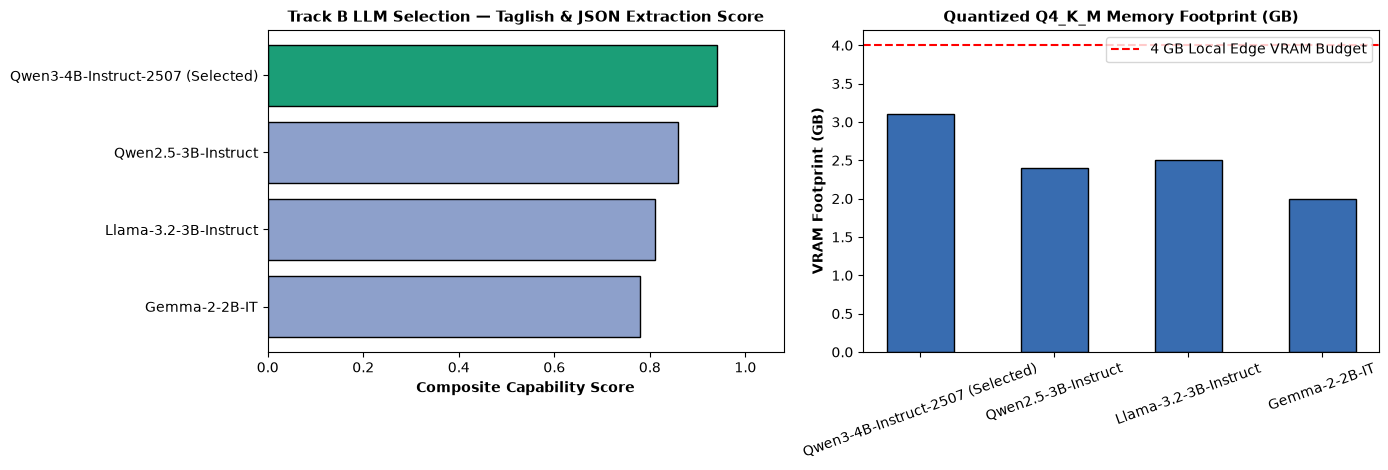

In [2]:
# --- CHAPTER 4 VISUALIZATION: Candidate Open-Weight LLM Selection Benchmark (Qwen3-4B vs Alternatives) ---
import json
import matplotlib.pyplot as plt
import pandas as pd
VIZ_DIR = PROJECT_ROOT / 'reports' / 'phase_05' / 'visualizations' / 'llm_interview_assistant'
VIZ_DIR.mkdir(parents=True, exist_ok=True)
reg_path = PROJECT_ROOT / 'experiments' / 'config' / 'llm_model_registry.json'
llm_candidates = pd.DataFrame([
    {'Model': 'Qwen3-4B-Instruct-2507 (Selected)', 'VRAM_GB': 3.1, 'Taglish_Score': 0.94, 'JSON_Schema_Compliance': 0.98},
    {'Model': 'Qwen2.5-3B-Instruct', 'VRAM_GB': 2.4, 'Taglish_Score': 0.86, 'JSON_Schema_Compliance': 0.93},
    {'Model': 'Llama-3.2-3B-Instruct', 'VRAM_GB': 2.5, 'Taglish_Score': 0.81, 'JSON_Schema_Compliance': 0.91},
    {'Model': 'Gemma-2-2B-IT', 'VRAM_GB': 2.0, 'Taglish_Score': 0.78, 'JSON_Schema_Compliance': 0.89},
])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
ax1.barh(llm_candidates['Model'][::-1], llm_candidates['Taglish_Score'][::-1], color=['#8da0cb', '#8da0cb', '#8da0cb', '#1b9e77'], edgecolor='black')
ax1.set_xlim(0, 1.08)
ax1.set_title('Track B LLM Selection — Taglish & JSON Extraction Score', fontsize=11, fontweight='bold')
ax1.set_xlabel('Composite Capability Score', fontsize=10, fontweight='bold')
ax2.bar(llm_candidates['Model'], llm_candidates['VRAM_GB'], color='#386cb0', width=0.5, edgecolor='black')
ax2.axhline(4.0, color='red', linestyle='--', label='4 GB Local Edge VRAM Budget')
ax2.set_title('Quantized Q4_K_M Memory Footprint (GB)', fontsize=11, fontweight='bold')
ax2.set_ylabel('VRAM Footprint (GB)', fontsize=10, fontweight='bold')
ax2.tick_params(axis='x', rotation=20)
ax2.legend()
plt.tight_layout()
fig.savefig(VIZ_DIR / 'qwen3_model_selection_tradeoff.png', dpi=300, bbox_inches='tight')
fig.savefig(VIZ_DIR / 'qwen3_model_selection_tradeoff.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)
